# Homework 10 Solutions

In [1]:
# This is a code cell that imports the necessary libraries for our session.
import numpy as np                        # NumPy for numerical computations
import scipy as sp                        # SciPy for scientific computing
import sympy as sym                       # SymPy for symbolic mathematics
import matplotlib as mpl                  # Matplotlib for plotting
import matplotlib.pyplot as plt           # Matplotlib pyplot interface
from matplotlib.lines import Line2D       # Legend entries for hand-built legends
from scipy.integrate import solve_ivp     # ODE solver
mpl.rcParams['figure.dpi'] = 150
mpl.rcParams['axes.spines.top'] = False
mpl.rcParams['axes.spines.right'] = False

This page collects full solutions to the exercises from Homework 10
(Logan, Chapter 5, Nonlinear Systems, pp. 257–258). Each solution is
worked out “by hand” and then confirmed symbolically using SymPy. The
nullclines and the direction of the flow in the regions they bound are
worked out by hand in the text; the figures simply display what the sign
analysis says, next to a phase portrait that plays the role of the phase
plane web app. See the [Homework
Solutions](https://math341diffeq.netlify.app/select_hw_solutions) page
for the full list.

## The method

For an autonomous system $x'=f(x,y)$, $y'=g(x,y)$ we proceed in four
steps.

1.  **Critical points.** Solve $f(x,y)=0,\ g(x,y)=0$ simultaneously.
2.  **Linearize.** At each critical point $(x^*,y^*)$ compute the
    Jacobian matrix $$
    J(x^*,y^*)=\begin{pmatrix} f_x & f_y\\ g_x & g_y\end{pmatrix}\Bigg|_{(x^*,y^*)},
    $$ and classify the point by $\tau=\operatorname{tr}J$,
    $\Delta=\det J$ and the eigenvalues of $J$:

| Eigenvalues of $J$ | Type of critical point | Stability |
|:-----------------------|:-----------------------|:-----------------------|
| $\Delta<0$ (real, opposite signs) | saddle | unstable |
| real, both negative | node (possibly degenerate) | asymptotically stable |
| real, both positive | node (possibly degenerate) | unstable |
| $\alpha\pm i\beta$, $\alpha<0$ | spiral | asymptotically stable |
| $\alpha\pm i\beta$, $\alpha>0$ | spiral | unstable |
| $\pm i\beta$ | center *for the linear system*; the nonlinear system could be a center or a spiral | inconclusive |

1.  **Nullclines.** The curve $f=0$ is where the flow is purely
    vertical, and the curve $g=0$ is where it is purely horizontal.
    Between nullclines the signs of $x'$ and $y'$ do not change, so the
    direction of the flow is one of
    $\nearrow,\ \nwarrow,\ \swarrow,\ \searrow$ throughout each region.
2.  **Phase diagram.** Combine the equilibria, their types, and the
    region arrows into a sketch of key orbits. At a saddle, the stable
    and unstable manifolds (the *separatrices*) are tangent to the
    eigenvectors of $J$ and organize the whole picture.

By the Hartman–Grobman theorem, if no eigenvalue of $J$ has zero real
part, the linearization gives the correct local picture (the type of the
critical point and its stability). Two code cells below are shared by
all the exercises and are defined here once: one analyzes a system
symbolically, and one draws the two-panel figure. Because the kernel is
shared, they are available on the rest of the page.

In [2]:
x, y = sym.symbols('x y', real=True)

def classify_point(J):
    """Classify a critical point from its Jacobian J (a 2x2 sympy Matrix)."""
    tr, det = sym.simplify(J.trace()), sym.simplify(J.det())
    disc = sym.simplify(tr**2 - 4*det)
    if det < 0:
        return "saddle (unstable)"
    if det == 0 or (tr == 0 and det > 0):
        return "borderline: linearization inconclusive"
    if disc < 0:
        if tr < 0: return "stable (asymptotically) spiral"
        if tr > 0: return "unstable spiral"
        return "center for the linearization (inconclusive)"
    kind = "degenerate node" if disc == 0 else "node"
    return ("stable (asymptotically) " if tr < 0 else "unstable ") + kind

def analyze(f, g, label):
    """Find the critical points of x'=f, y'=g and classify each by its Jacobian."""
    J = sym.Matrix([f, g]).jacobian([x, y])
    pts = sym.solve([f, g], [x, y], dict=True)
    print(f"{label}:  Jacobian = {J.tolist()}")
    for p in pts:
        Jp = J.subs(p)
        ev = {sym.nsimplify(sym.simplify(k)): m for k, m in Jp.eigenvals().items()}
        print(f"   ({p[x]}, {p[y]}):  J = {Jp.tolist()},  tr = {sym.simplify(Jp.trace())},"
              f"  det = {sym.simplify(Jp.det())},  eigenvalues = {list(ev)}")
        print(f"        -> {classify_point(Jp)}")
    return pts, J

def arrow(sx, sy):
    """Direction symbol from the signs of x' and y'."""
    return {(1, 1): "NE", (-1, 1): "NW", (-1, -1): "SW", (1, -1): "SE"}[(sx, sy)]

def check_regions(f, g, samples, label):
    """Evaluate the signs of x', y' at a sample point in each region and compare with the hand analysis."""
    F, G = sym.lambdify((x, y), f, 'numpy'), sym.lambdify((x, y), g, 'numpy')
    ok = True
    for (px, py), expected in samples:
        got = (int(np.sign(F(px, py))), int(np.sign(G(px, py))))
        if got != expected:
            ok = False
            print(f"  MISMATCH at ({px}, {py}): got {got}, expected {expected}")
    print(f"{label}: region arrows agree with the hand analysis at all {len(samples)} sample points: {ok}")

In [3]:
def nullcline_and_portrait(f, g, xlim, ylim, title, pts_J, n_arrows=11, density=1.3):
    """Left panel: nullclines, equilibria and direction arrows.
       Right panel: phase portrait (streamlines) with saddle separatrices."""
    F = sym.lambdify((x, y), f, 'numpy'); G = sym.lambdify((x, y), g, 'numpy')
    xs = np.linspace(*xlim, 500); ys = np.linspace(*ylim, 500)
    X, Y = np.meshgrid(xs, ys)
    FX, GY = F(X, Y) + 0*X, G(X, Y) + 0*X

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.9))
    for ax in axes:
        ax.contour(X, Y, FX, levels=[0], colors='tab:purple', linewidths=1.8)
        ax.contour(X, Y, GY, levels=[0], colors='darkorange', linewidths=1.8, linestyles='--')
        ax.axhline(0, color='gray', lw=0.5, zorder=0); ax.axvline(0, color='gray', lw=0.5, zorder=0)
        ax.set_xlim(xlim); ax.set_ylim(ylim); ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$y$")

    # Left: normalized direction arrows on a coarse grid
    gx = np.linspace(xlim[0], xlim[1], n_arrows+2)[1:-1]; gy = np.linspace(ylim[0], ylim[1], n_arrows+2)[1:-1]
    GX, GYY = np.meshgrid(gx, gy)
    U, V = F(GX, GYY) + 0*GX, G(GX, GYY) + 0*GX
    N = np.hypot(U, V); N[N == 0] = 1
    dx, dy = gx[1]-gx[0], gy[1]-gy[0]
    axes[0].quiver(GX, GYY, 0.5*dx*U/N, 0.5*dy*V/N, angles='xy', scale_units='xy', scale=1,
                   pivot='mid', width=0.004, color='dimgray', zorder=1)
    axes[0].set_title("Nullclines and direction of the flow")

    # Right: streamlines
    U2, V2 = F(X, Y) + 0*X, G(X, Y) + 0*X
    axes[1].streamplot(xs, ys, U2, V2, color='steelblue', density=density, linewidth=0.9, arrowsize=1.1)
    axes[1].set_title("Phase portrait")

    # Equilibria, colored by type; separatrices at saddles
    def out(tt, z):
        return min(z[0]-xlim[0], xlim[1]-z[0], z[1]-ylim[0], ylim[1]-z[1])
    out.terminal = True
    for (px, py), J in pts_J:
        Jn = np.array(J, dtype=float)
        det, tr = np.linalg.det(Jn), np.trace(Jn)
        color = 'black' if det < 0 else ('tab:blue' if tr < 0 else 'tab:red')
        marker = 's' if det < 0 else 'o'
        for ax in axes:
            ax.plot(px, py, marker, ms=8, mfc=color, mec='black', zorder=6)
        if det < 0:
            w, V_ = np.linalg.eig(Jn)
            for lam, v in zip(w.real, V_.T.real):
                for sgn in (1, -1):
                    z0 = np.array([px, py]) + sgn*1e-4*v
                    direction = 1 if lam > 0 else -1          # unstable manifold: forward; stable: backward
                    rhs = lambda tt, z, d=direction: d*np.array([F(z[0], z[1]), G(z[0], z[1])])
                    sol = solve_ivp(rhs, (0, 60), z0, events=out, rtol=1e-9, atol=1e-11, max_step=0.05)
                    axes[1].plot(sol.y[0], sol.y[1], color='seagreen' if lam > 0 else 'crimson', lw=2.4, zorder=5)

    handles = [Line2D([], [], color='tab:purple', lw=1.8, label=r"$x'=0$ (vertical flow)"),
               Line2D([], [], color='darkorange', lw=1.8, ls='--', label=r"$y'=0$ (horizontal flow)"),
               Line2D([], [], marker='o', ls='', mfc='tab:blue', mec='k', label='stable'),
               Line2D([], [], marker='o', ls='', mfc='tab:red', mec='k', label='unstable'),
               Line2D([], [], marker='s', ls='', mfc='black', mec='k', label='saddle')]
    if any(np.linalg.det(np.array(J, dtype=float)) < 0 for _, J in pts_J):
        handles += [Line2D([], [], color='seagreen', lw=2.4, label='unstable manifold'),
                    Line2D([], [], color='crimson', lw=2.4, label='stable manifold')]
    fig.legend(handles=handles, loc='lower center', ncol=len(handles), fontsize=8, frameon=False)
    fig.suptitle(title, y=1.0)
    plt.tight_layout(rect=[0, 0.07, 1, 1]); plt.show()

def pts_with_J(f, g, pts):
    """Attach the numerical Jacobian to each critical point (for the figure helper)."""
    J = sym.Matrix([f, g]).jacobian([x, y])
    return [((float(p[x]), float(p[y])), [[float(e) for e in row] for row in J.subs(p).tolist()]) for p in pts]

## Chapter 5 — Nonlinear Systems

### Exercise 1, Page 257

For each system: (a) find all critical points; (b) use the Jacobian
matrix to classify them; (c) sketch the nullclines and indicate the
direction field in the regions they bound; (d) sketch a rough phase
diagram with several key orbits.

#### Part (a): $x'=x-y,\ y'=2x(-1+y)$

**Critical points.** Setting $x'=0$ gives $y=x$. Then $y'=2x(y-1)=0$
gives $x=0$ or $y=1$. So the critical points are $$
\boxed{(0,0)\quad\text{and}\quad(1,1).}
$$

**Classification.** With $f=x-y$ and $g=2x(y-1)$ we have
$f_x=1,\ f_y=-1,\ g_x=2(y-1),\ g_y=2x$, so $$
J(x,y)=\begin{pmatrix}1&-1\\2(y-1)&2x\end{pmatrix}.
$$

- At $(0,0)$: $J=\begin{pmatrix}1&-1\\-2&0\end{pmatrix}$, with
  $\Delta=-2<0$. The eigenvalues satisfy
  $\lambda^2-\lambda-2=(\lambda-2)(\lambda+1)=0$, so $\lambda=2,-1$. It
  is a **saddle** (unstable).
- At $(1,1)$: $J=\begin{pmatrix}1&-1\\0&2\end{pmatrix}$ is upper
  triangular, so $\lambda=1,2$. Both are positive, so it is an
  **unstable node**.

**Nullclines and direction field.** The $x'=0$ nullcline is the line
$y=x$, and $x'>0$ below it ($y<x$). The $y'=0$ nullclines are the lines
$x=0$ and $y=1$, and $y'>0$ when $x(y-1)>0$, that is, when $x>0,\,y>1$
or $x<0,\,y<1$. These three lines cut the plane into seven regions:

| Region                       | Sign of $x'$ | Sign of $y'$ | Flow |
|:-----------------------------|:------------:|:------------:|:----:|
| $x>0,\ y>1,\ y>x$            |     $-$      |     $+$      |  NW  |
| $x>0,\ y>1,\ y<x$            |     $+$      |     $+$      |  NE  |
| $x>0,\ y<1,\ y<x$            |     $+$      |     $-$      |  SE  |
| $x>0,\ y<1,\ y>x$ (triangle) |     $-$      |     $-$      |  SW  |
| $x<0,\ y<1,\ y>x$            |     $-$      |     $+$      |  NW  |
| $x<0,\ y<x$                  |     $+$      |     $+$      |  NE  |
| $x<0,\ y>1$                  |     $-$      |     $-$      |  SW  |

The saddle at the origin is where all four arrow directions meet in an
alternating pattern, and in the triangle with vertices
$(0,0),(0,1),(1,1)$ the flow points SW toward the origin.

**SymPy check.**

In [4]:
f1a, g1a = x - y, 2*x*(-1 + y)
pts, J = analyze(f1a, g1a, "1(a)")
check_regions(f1a, g1a, [((0.5, 2), (-1, 1)), ((3, 2), (1, 1)), ((2, 0), (1, -1)), ((0.5, 0.8), (-1, -1)),
                         ((-1, 0), (-1, 1)), ((-1, -2), (1, 1)), ((-1, 2), (-1, -1))], "1(a)")

1(a):  Jacobian = [[1, -1], [2*y - 2, 2*x]]
   (0, 0):  J = [[1, -1], [-2, 0]],  tr = 1,  det = -2,  eigenvalues = [2, -1]
        -> saddle (unstable)
   (1, 1):  J = [[1, -1], [0, 2]],  tr = 3,  det = 2,  eigenvalues = [2, 1]
        -> unstable node
1(a): region arrows agree with the hand analysis at all 7 sample points: True

> **Note**
>
> SymPy confirms the critical points $(0,0)$ and $(1,1)$, the saddle and
> unstable node classification, and the sign of $x'$ and $y'$ in each of
> the seven regions.

**Phase diagram.**

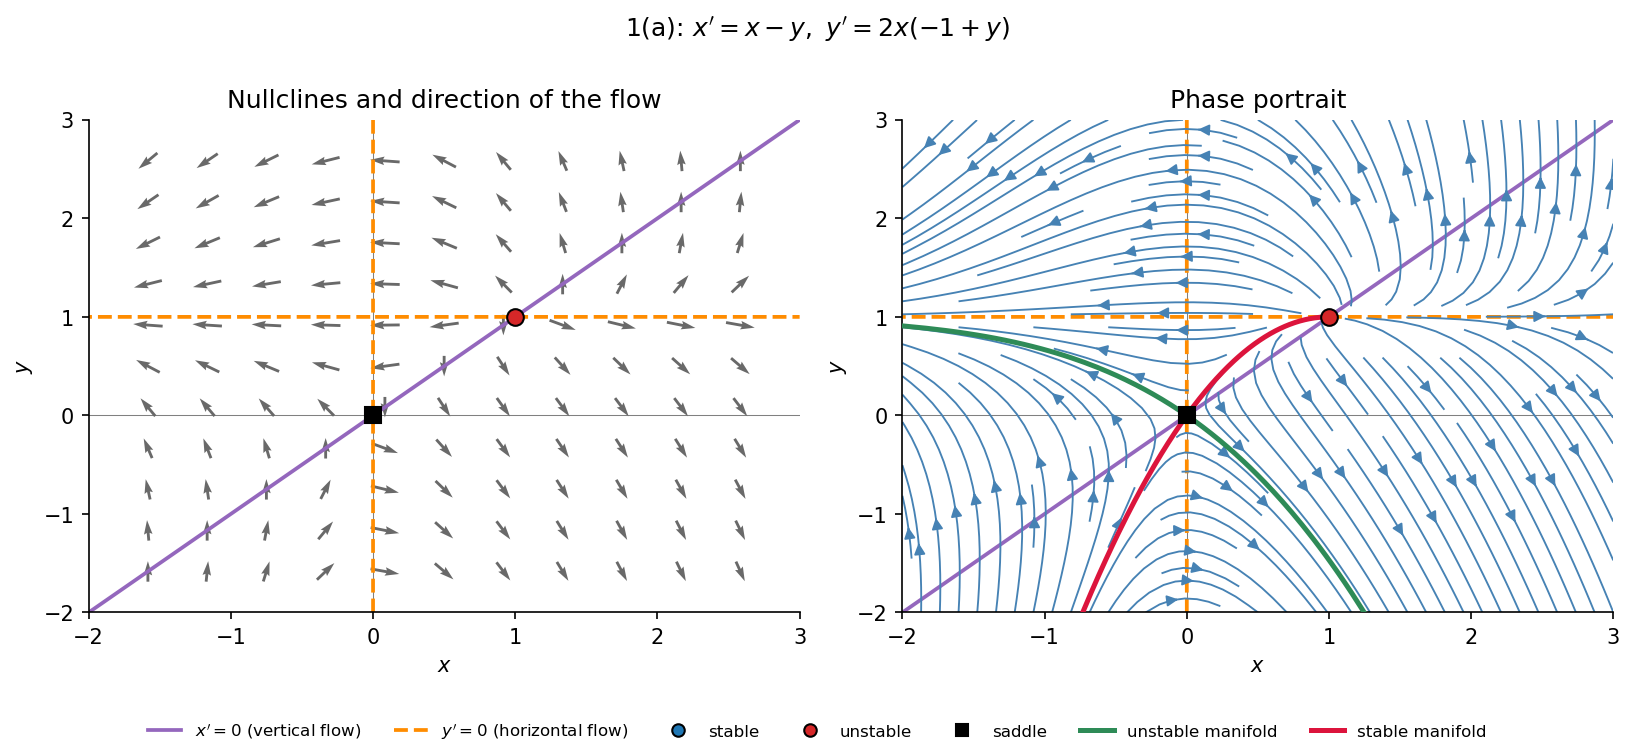

In [5]:
nullcline_and_portrait(f1a, g1a, (-2, 3), (-2, 3), r"1(a): $x'=x-y,\ y'=2x(-1+y)$", pts_with_J(f1a, g1a, pts))

The flow near the saddle at the origin enters along the stable manifold
(red, tangent to the eigenvector for $\lambda=-1$) and leaves along the
unstable manifold (green, $\lambda=2$). Everything near $(1,1)$ moves
away from it, as expected for an unstable node.

#### Part (b): $x'=x-xy^2,\ y'=x+y$

**Critical points.** From $x'=x(1-y^2)=0$ we get $x=0$ or $y=\pm1$. If
$x=0$, then $y'=y=0$. If $y=1$, then $x=-1$, and if $y=-1$, then $x=1$.
So $$
\boxed{(0,0),\quad(-1,1),\quad(1,-1).}
$$

**Classification.** Here
$J(x,y)=\begin{pmatrix}1-y^2&-2xy\\1&1\end{pmatrix}$.

- At $(0,0)$: $J=\begin{pmatrix}1&0\\1&1\end{pmatrix}$ has the repeated
  eigenvalue $\lambda=1$ with a single eigenvector $(0,1)$. It is an
  **unstable (degenerate) node**. The eigenvalue has nonzero real part,
  so by Hartman–Grobman the nonlinear system is also an unstable node
  near the origin.
- At $(-1,1)$ and $(1,-1)$: $-2xy=2$ at both points, so
  $J=\begin{pmatrix}0&2\\1&1\end{pmatrix}$ at both. Then $\Delta=-2<0$
  and $\lambda^2-\lambda-2=0$ gives $\lambda=2,-1$. Both are
  **saddles**.

**Nullclines and direction field.** The $x'=0$ nullclines are $x=0$ and
$y=\pm1$, and $x'>0$ exactly when $x(1-y^2)>0$, that is, $x>0$ with
$|y|<1$ or $x<0$ with $|y|>1$. The $y'=0$ nullcline is the line $y=-x$,
with $y'>0$ above it. These four lines cut the plane into eleven
regions. The flow near the origin is:

- $x>0$, $|y|<1$ and $y>-x$: NE, and the same region below the line
  ($y<-x$) is SE;
- $x<0$, $|y|<1$ and $y>-x$: NW, and below the line it is SW.

Around the saddle $(-1,1)$ the four neighboring regions give NE (above
the line, $y>1$), SW (below the line, $|y|<1$), SE ($y>1$ and $y<-x$),
and NW ($|y|<1$ and $y>-x$) in alternating positions, the pattern of a
saddle. The system is invariant under $(x,y)\mapsto(-x,-y)$, so the
picture at $(1,-1)$ is the point reflection of the picture at $(-1,1)$.

**SymPy check.**

In [6]:
f1b, g1b = x - x*y**2, x + y
pts, J = analyze(f1b, g1b, "1(b)")
check_regions(f1b, g1b, [((-1.5, 1.2), (1, -1)), ((-0.5, 1.5), (1, 1)), ((-1.5, 0.8), (-1, -1)), ((-0.5, 0.8), (-1, 1)),
                         ((1, 2), (-1, 1)), ((1, 0), (1, 1)), ((0.5, -0.9), (1, -1)), ((3, -2), (-1, 1)),
                         ((1, -2), (-1, -1)), ((-1, -2), (1, -1)), ((-3, 2), (1, -1))], "1(b)")

1(b):  Jacobian = [[1 - y**2, -2*x*y], [1, 1]]
   (-1, 1):  J = [[0, 2], [1, 1]],  tr = 1,  det = -2,  eigenvalues = [2, -1]
        -> saddle (unstable)
   (0, 0):  J = [[1, 0], [1, 1]],  tr = 2,  det = 1,  eigenvalues = [1]
        -> unstable degenerate node
   (1, -1):  J = [[0, 2], [1, 1]],  tr = 1,  det = -2,  eigenvalues = [2, -1]
        -> saddle (unstable)
1(b): region arrows agree with the hand analysis at all 11 sample points: True

> **Note**
>
> SymPy confirms the three critical points, the repeated eigenvalue
> $\lambda=1$ at the origin, the two saddles, and the direction of the
> flow in all eleven regions.

**Phase diagram.**

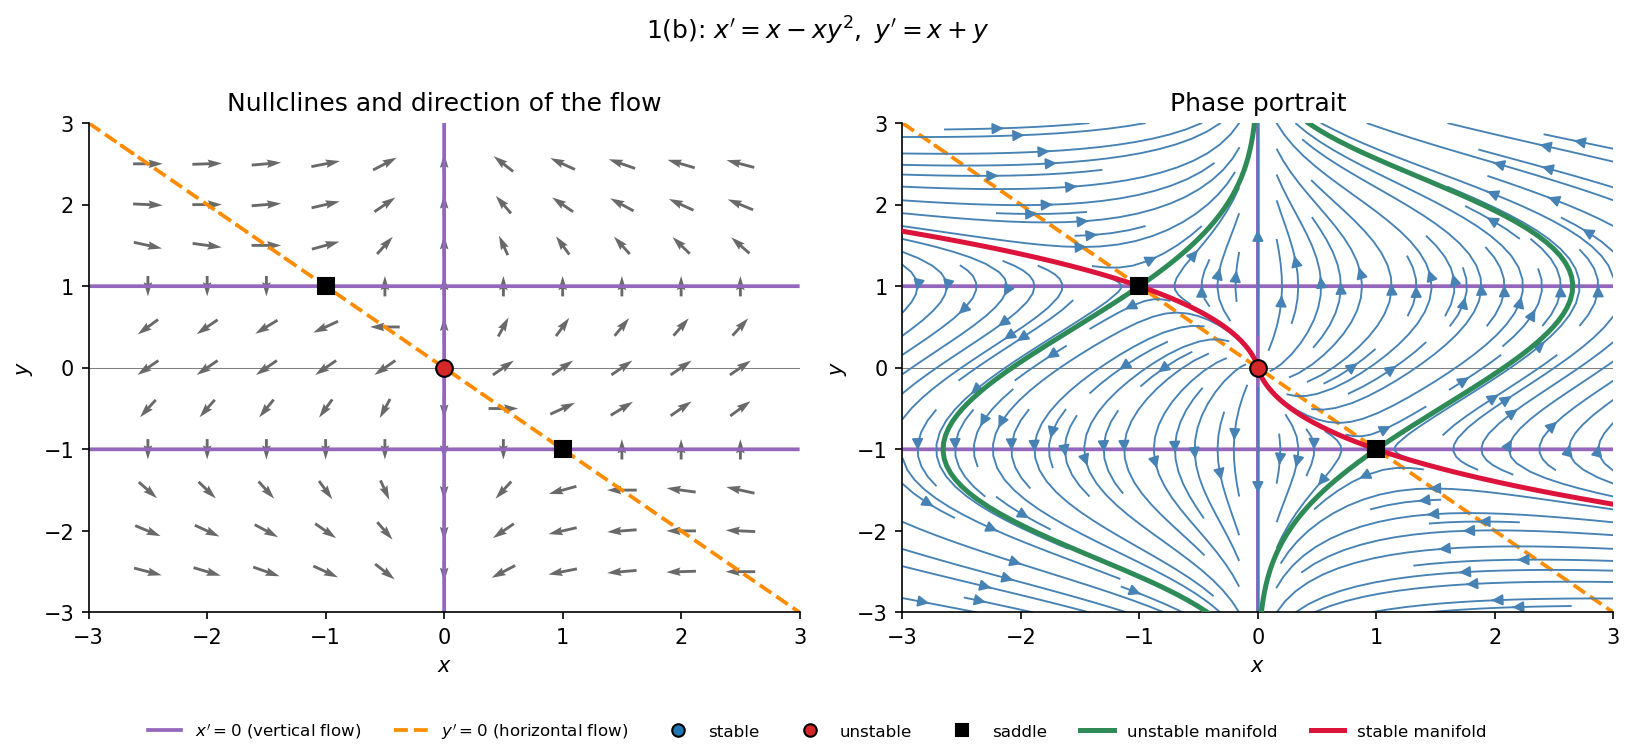

In [7]:
nullcline_and_portrait(f1b, g1b, (-3, 3), (-3, 3), r"1(b): $x'=x-xy^2,\ y'=x+y$", pts_with_J(f1b, g1b, pts))

#### Part (c): $x'=1-x^2,\ y'=y+2$

**Critical points.** $x'=0$ gives $x=\pm1$ and $y'=0$ gives $y=-2$, so
$$
\boxed{(1,-2)\quad\text{and}\quad(-1,-2).}
$$

**Classification.** $J=\begin{pmatrix}-2x&0\\0&1\end{pmatrix}$ is
diagonal.

- At $(1,-2)$: $J=\operatorname{diag}(-2,1)$, so the eigenvalues have
  opposite signs and it is a **saddle**.
- At $(-1,-2)$: $J=\operatorname{diag}(2,1)$, so both are positive and
  it is an **unstable node**.

**Nullclines and direction field.** The $x'=0$ nullclines are the
vertical lines $x=\pm1$, with $x'>0$ for $|x|<1$ and $x'<0$ for $|x|>1$.
The $y'=0$ nullcline is the horizontal line $y=-2$, with $y'>0$ above
it. The six regions are:

|        | $x<-1$ | $-1<x<1$ | $x>1$ |
|:-------|:------:|:--------:|:-----:|
| $y>-2$ |   NW   |    NE    |  NW   |
| $y<-2$ |   SW   |    SE    |  SW   |

Since the system is uncoupled, all three lines are also invariant sets:
a solution that starts on $x=1$ stays there. These lines are the
separatrices of the saddle at $(1,-2)$.

**SymPy check.**

In [8]:
f1c, g1c = 1 - x**2, y + 2
pts, J = analyze(f1c, g1c, "1(c)")
check_regions(f1c, g1c, [((-2, 0), (-1, 1)), ((0, 0), (1, 1)), ((2, 0), (-1, 1)),
                         ((-2, -3), (-1, -1)), ((0, -3), (1, -1)), ((2, -3), (-1, -1))], "1(c)")

1(c):  Jacobian = [[-2*x, 0], [0, 1]]
   (-1, -2):  J = [[2, 0], [0, 1]],  tr = 3,  det = 2,  eigenvalues = [2, 1]
        -> unstable node
   (1, -2):  J = [[-2, 0], [0, 1]],  tr = -1,  det = -2,  eigenvalues = [-2, 1]
        -> saddle (unstable)
1(c): region arrows agree with the hand analysis at all 6 sample points: True

> **Note**
>
> SymPy confirms the two critical points, the diagonal Jacobians with
> the eigenvalues above, and the six region arrows.

**Phase diagram.**

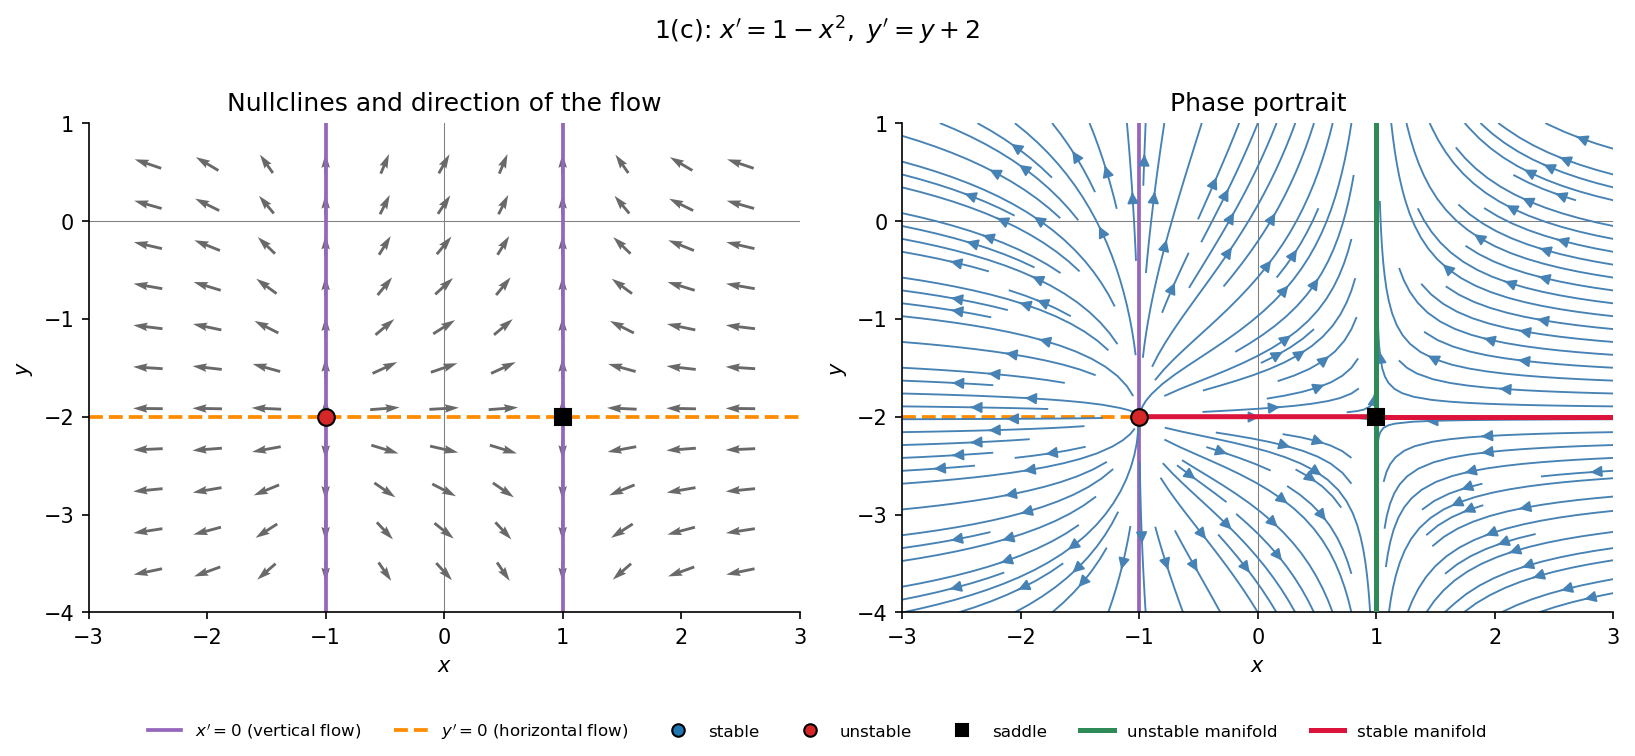

In [9]:
nullcline_and_portrait(f1c, g1c, (-3, 3), (-4, 1), r"1(c): $x'=1-x^2,\ y'=y+2$", pts_with_J(f1c, g1c, pts))

#### Part (d): $x'=-x+xy,\ y'=-2y(1-4x)$

**Critical points.** $x'=x(y-1)=0$ gives $x=0$ or $y=1$. If $x=0$, then
$y'=-2y=0$, so $y=0$. If $y=1$, then $y'=-2(1-4x)=0$ gives $x=\tfrac14$.
So $$
\boxed{(0,0)\quad\text{and}\quad\left(\tfrac14,1\right).}
$$

**Classification.**
$J(x,y)=\begin{pmatrix}-1+y&x\\8y&-2+8x\end{pmatrix}$.

- At $(0,0)$: $J=\begin{pmatrix}-1&0\\0&-2\end{pmatrix}$, so
  $\lambda=-1,-2$. It is a **stable node** (asymptotically stable).
- At $\left(\tfrac14,1\right)$:
  $J=\begin{pmatrix}0&\tfrac14\\8&0\end{pmatrix}$ has $\Delta=-2<0$, and
  $\lambda^2=2$ gives $\lambda=\pm\sqrt2$. It is a **saddle**.

**Nullclines and direction field.** The $x'=0$ nullclines are $x=0$ and
$y=1$, and $x'>0$ when $x>0,\,y>1$ or $x<0,\,y<1$. The $y'=0$ nullclines
are $y=0$ and $x=\tfrac14$, and $y'>0$ when $y(1-4x)<0$, that is, $y>0$
with $x>\tfrac14$, or $y<0$ with $x<\tfrac14$. Near the origin the four
regions give

- $x>0,\ y>0$ small: SW, and $x<0,\ y>0$: SE,
- $x<0,\ y<0$: NE, and $x>0,\ y<0$: NW,

so the arrows in all four quadrants point toward the origin, consistent
with a stable node. Near $\left(\tfrac14,1\right)$ the four regions give
NE ($x>\tfrac14,\ y>1$), SE ($x<\tfrac14,\ y>1$), SW
($x<\tfrac14,\ y<1$) and NW ($x>\tfrac14,\ y<1$), an alternating
pattern, consistent with a saddle.

**SymPy check.**

In [10]:
f1d, g1d = -x + x*y, -2*y*(1 - 4*x)
pts, J = analyze(f1d, g1d, "1(d)")
check_regions(f1d, g1d, [((0.1, 0.5), (-1, -1)), ((-0.5, 0.5), (1, -1)), ((0.1, -0.5), (-1, 1)), ((-0.5, -0.5), (1, 1)),
                         ((0.5, 1.5), (1, 1)), ((0.1, 1.5), (1, -1)), ((0.5, 0.5), (-1, 1))], "1(d)")

1(d):  Jacobian = [[y - 1, x], [8*y, 8*x - 2]]
   (0, 0):  J = [[-1, 0], [0, -2]],  tr = -3,  det = 2,  eigenvalues = [-1, -2]
        -> stable (asymptotically) node
   (1/4, 1):  J = [[0, 1/4], [8, 0]],  tr = 0,  det = -2,  eigenvalues = [-sqrt(2), sqrt(2)]
        -> saddle (unstable)
1(d): region arrows agree with the hand analysis at all 7 sample points: True

> **Note**
>
> SymPy confirms the critical points, the stable node at the origin, the
> saddle at $\left(\tfrac14,1\right)$ with $\lambda=\pm\sqrt2$, and the
> signs of $x'$ and $y'$ in the sampled regions.

**Phase diagram.**

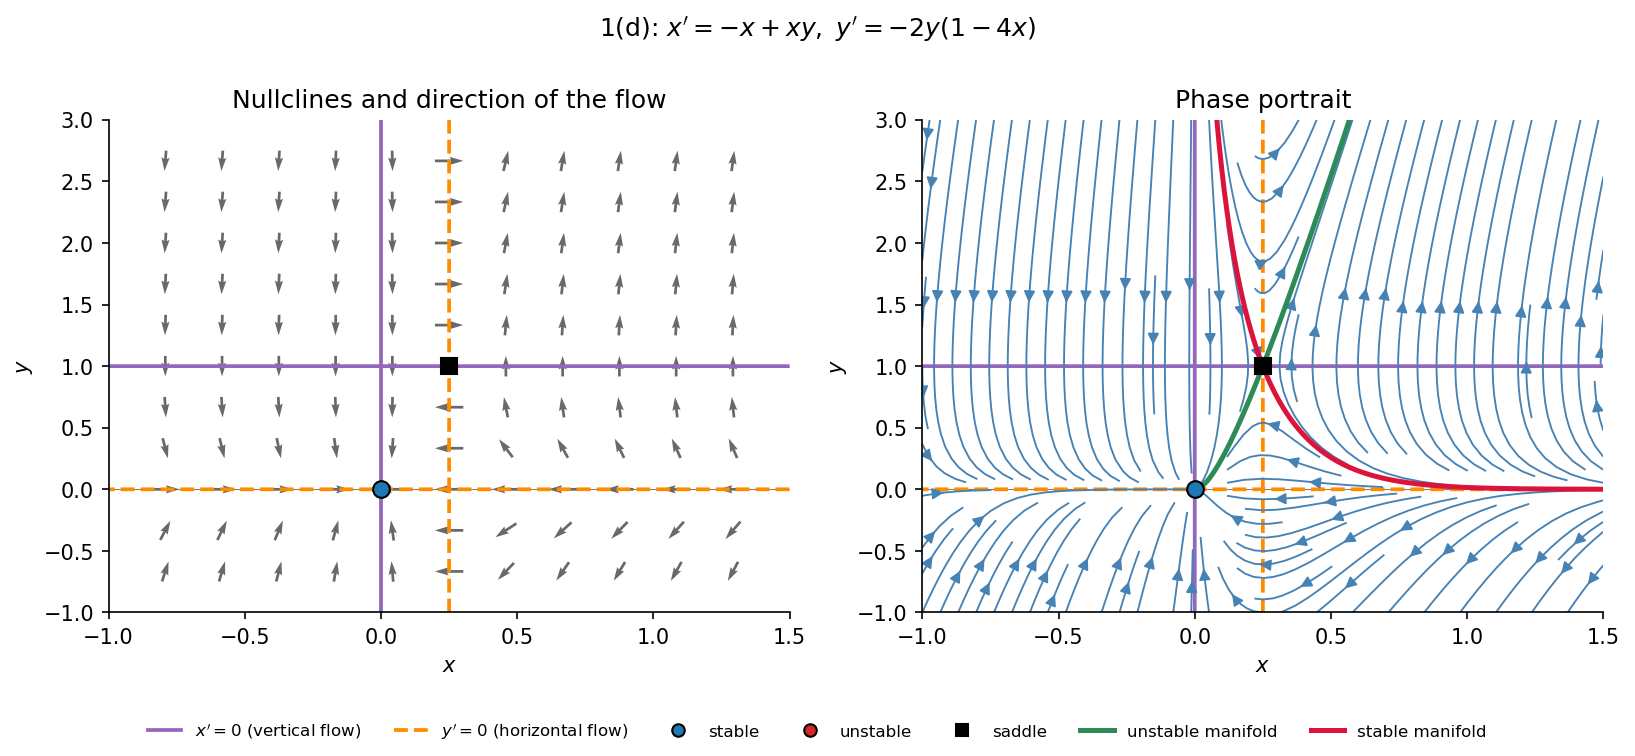

In [11]:
nullcline_and_portrait(f1d, g1d, (-1, 1.5), (-1, 3), r"1(d): $x'=-x+xy,\ y'=-2y(1-4x)$", pts_with_J(f1d, g1d, pts))

#### Part (e): $x'=x-y+x^2,\ y'=x+y$

**Critical points.** $y'=0$ gives $y=-x$. Then $x'=x+x+x^2=x(x+2)=0$
gives $x=0$ or $x=-2$. So $$
\boxed{(0,0)\quad\text{and}\quad(-2,2).}
$$

**Classification.** $J(x,y)=\begin{pmatrix}1+2x&-1\\1&1\end{pmatrix}$.

- At $(0,0)$: $J=\begin{pmatrix}1&-1\\1&1\end{pmatrix}$ has $\tau=2$,
  $\Delta=2$, and $\lambda^2-2\lambda+2=0$ gives $\lambda=1\pm i$. It is
  an **unstable spiral**.
- At $(-2,2)$: $J=\begin{pmatrix}-3&-1\\1&1\end{pmatrix}$ has $\tau=-2$,
  $\Delta=-2<0$, and $\lambda^2+2\lambda-2=0$ gives
  $\lambda=-1\pm\sqrt3$. These have opposite signs, so it is a
  **saddle**.

**Nullclines and direction field.** The $x'=0$ nullcline is the parabola
$y=x+x^2$, with $x'>0$ below it. The $y'=0$ nullcline is the line
$y=-x$, with $y'>0$ above it. They cross at the two critical points.
Around the origin the four regions are

- above both curves: NW (e.g. at $(0,1)$); to the left, above the
  parabola and below the line: SW;
- below both curves: SE (e.g. at $(0,-1)$); to the right, below the
  parabola and above the line: NE.

Going around the origin the arrows point N→NW, W→SW, S→SE, E→NE, which
is a counterclockwise circulation. Together with the positive real part
of the eigenvalues this gives a spiral that unwinds counterclockwise.

**SymPy check.**

In [12]:
f1e, g1e = x - y + x**2, x + y
pts, J = analyze(f1e, g1e, "1(e)")
check_regions(f1e, g1e, [((0, 1), (-1, 1)), ((-0.5, 0), (-1, -1)), ((0, -1), (1, -1)), ((0.5, 0), (1, 1))], "1(e)")

1(e):  Jacobian = [[2*x + 1, -1], [1, 1]]
   (-2, 2):  J = [[-3, -1], [1, 1]],  tr = -2,  det = -2,  eigenvalues = [-sqrt(3) - 1, -1 + sqrt(3)]
        -> saddle (unstable)
   (0, 0):  J = [[1, -1], [1, 1]],  tr = 2,  det = 2,  eigenvalues = [1 - I, 1 + I]
        -> unstable spiral
1(e): region arrows agree with the hand analysis at all 4 sample points: True

> **Note**
>
> SymPy confirms the two critical points, the eigenvalues $1\pm i$ at
> the origin and $-1\pm\sqrt3$ at $(-2,2)$, and the counterclockwise
> pattern of the four arrows around the origin.

**Phase diagram.**

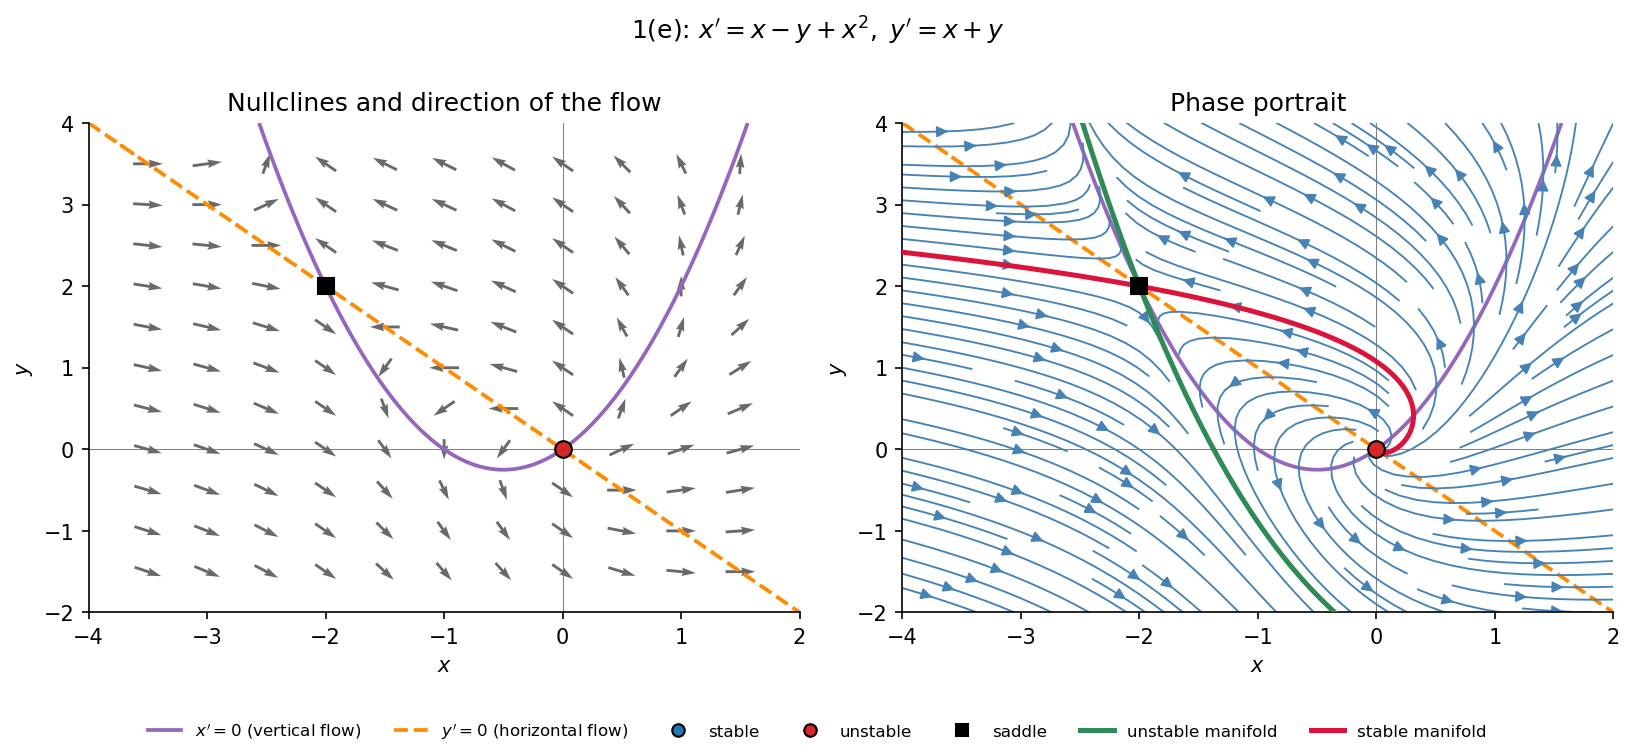

In [13]:
nullcline_and_portrait(f1e, g1e, (-4, 2), (-2, 4), r"1(e): $x'=x-y+x^2,\ y'=x+y$", pts_with_J(f1e, g1e, pts))

#### Part (f): $x'=-x-2y,\ y'=2x-y+xy^2$

*Note.* The statement of this part is missing the “$x'=$” on the first
equation. I have read it as $x'=-x-2y$.

**Critical points.** $x'=0$ gives $x=-2y$. Substituting in $y'=0$: $$
2(-2y)-y+(-2y)y^2=-5y-2y^3=-y(5+2y^2)=0.
$$ Since $5+2y^2>0$, the only real solution is $y=0$ (and then $x=0$).
The only critical point is $$
\boxed{(0,0).}
$$

**Classification.**
$J(x,y)=\begin{pmatrix}-1&-2\\2+y^2&-1+2xy\end{pmatrix}$, so
$J(0,0)=\begin{pmatrix}-1&-2\\2&-1\end{pmatrix}$ with $\tau=-2$,
$\Delta=5$, and $\lambda^2+2\lambda+5=0$ gives $\lambda=-1\pm2i$. It is
a **stable (asymptotically stable) spiral**.

**Nullclines and direction field.** The $x'=0$ nullcline is the line
$y=-x/2$, with $x'>0$ below it. The $y'=0$ nullcline is the curve
$x(2+y^2)=y$, that is, $x=\dfrac{y}{2+y^2}$, with $y'>0$ to the right of
it. Near the origin this curve looks like $y\approx2x$. The four regions
around the origin give

- E (e.g. $(1,0)$): NW; N (e.g. $(0,1)$): SW; W (e.g. $(-1,0)$): SE; S
  (e.g. $(0,-1)$): NE,

which is again a counterclockwise circulation, and with negative real
part the orbits spiral inward.

**SymPy check.**

In [14]:
f1f, g1f = -x - 2*y, 2*x - y + x*y**2
pts, J = analyze(f1f, g1f, "1(f)")
check_regions(f1f, g1f, [((1, 0), (-1, 1)), ((0, 1), (-1, -1)), ((-1, 0), (1, -1)), ((0, -1), (1, 1))], "1(f)")

1(f):  Jacobian = [[-1, -2], [y**2 + 2, 2*x*y - 1]]
   (0, 0):  J = [[-1, -2], [2, -1]],  tr = -2,  det = 5,  eigenvalues = [-1 - 2*I, -1 + 2*I]
        -> stable (asymptotically) spiral
1(f): region arrows agree with the hand analysis at all 4 sample points: True

> **Note**
>
> SymPy confirms that the origin is the only critical point, with
> eigenvalues $-1\pm2i$, and that the four arrows circulate
> counterclockwise.

**Phase diagram.**

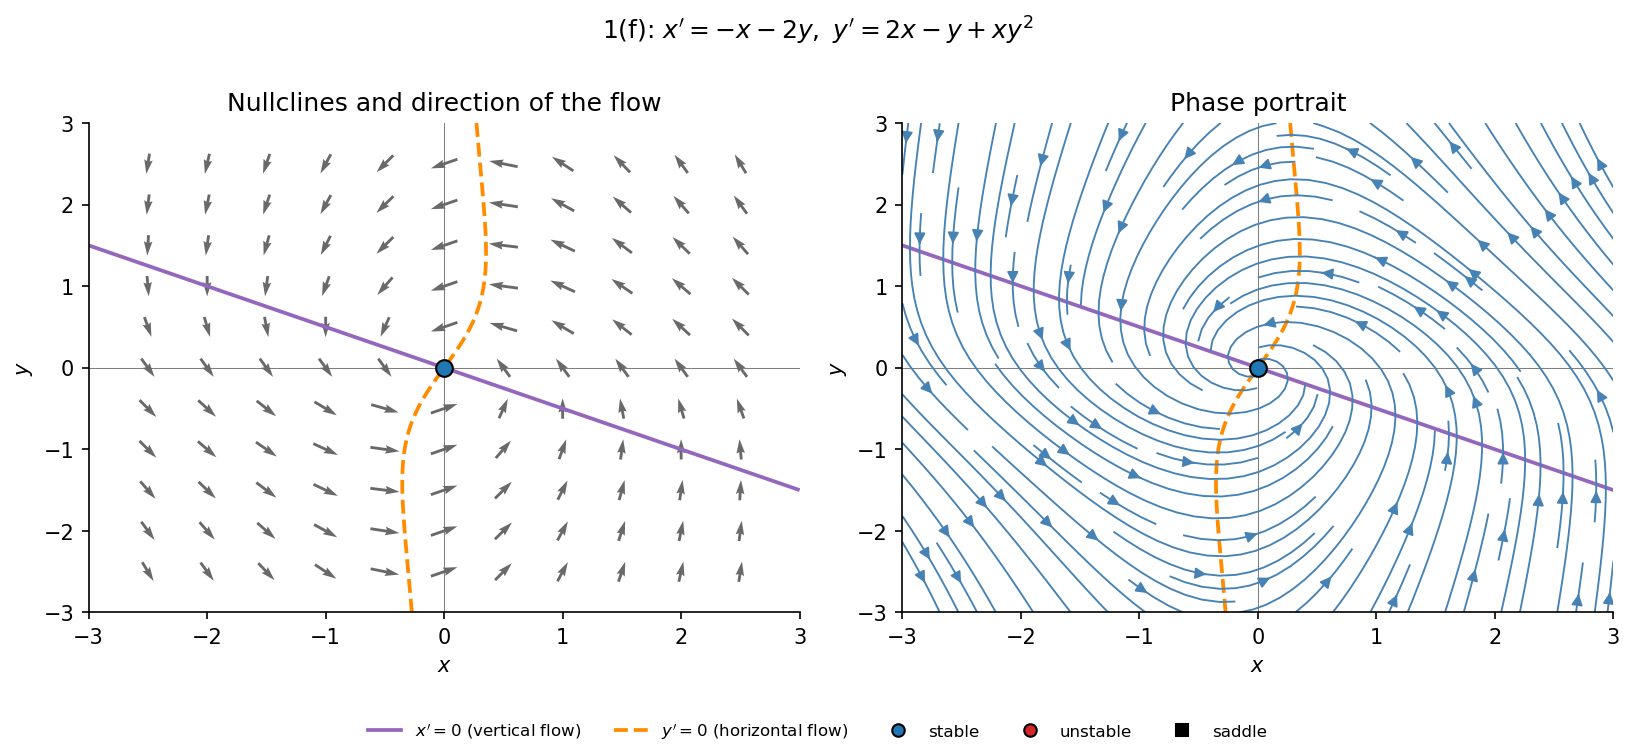

In [15]:
nullcline_and_portrait(f1f, g1f, (-3, 3), (-3, 3), r"1(f): $x'=-x-2y,\ y'=2x-y+xy^2$", pts_with_J(f1f, g1f, pts))

#### Summary of Exercise 1

| Part | Critical point | $J$ eigenvalues | Type |
|:-----------------|:-----------------|:-----------------|:-----------------|
| \(a\) | $(0,0)$ | $2,\,-1$ | saddle |
|  | $(1,1)$ | $1,\,2$ | unstable node |
| \(b\) | $(0,0)$ | $1,\,1$ (one eigenvector) | unstable (degenerate) node |
|  | $(-1,1)$ and $(1,-1)$ | $2,\,-1$ | saddles |
| \(c\) | $(1,-2)$ | $-2,\,1$ | saddle |
|  | $(-1,-2)$ | $2,\,1$ | unstable node |
| \(d\) | $(0,0)$ | $-1,\,-2$ | stable node |
|  | $\left(\tfrac14,1\right)$ | $\pm\sqrt2$ | saddle |
| \(e\) | $(0,0)$ | $1\pm i$ | unstable spiral |
|  | $(-2,2)$ | $-1\pm\sqrt3$ | saddle |
| \(f\) | $(0,0)$ | $-1\pm2i$ | stable spiral |

### Exercise 4, Pages 257–258

Consider the nonlinear system $x'=x^2+y^2-4,\ y'=y-2x$.

#### Part (a): the equilibria

From $y'=0$ we get $y=2x$. Substituting in $x'=0$: $$
x^2+4x^2-4=0\ \Longrightarrow\ x^2=\tfrac45\ \Longrightarrow\ x=\pm\tfrac{2}{\sqrt5}.
$$ So the two equilibria are $$
\boxed{P_+=\left(\tfrac{2}{\sqrt5},\tfrac{4}{\sqrt5}\right)\approx(0.894,\,1.789)\quad\text{and}\quad P_-=\left(-\tfrac{2}{\sqrt5},-\tfrac{4}{\sqrt5}\right)\approx(-0.894,\,-1.789).}
$$ Geometrically, they are the two points where the line $y=2x$ meets
the circle $x^2+y^2=4$. They are plotted in the figure below.

#### Part (b): the nullclines

- $x'=0$ on the **circle** $x^2+y^2=4$ of radius $2$ (vertical flow).
  The flow has $x'>0$ outside the circle and $x'<0$ inside.
- $y'=0$ on the **line** $y=2x$ (horizontal flow). The flow has $y'>0$
  above the line and $y'<0$ below.

#### Part (c): direction of the flow, and what we can conclude

The circle and the line cut the plane into four regions:

| Region                             | $x'$ | $y'$ | Flow |
|:-----------------------------------|:----:|:----:|:----:|
| outside the circle, above the line | $+$  | $+$  |  NE  |
| outside the circle, below the line | $+$  | $-$  |  SE  |
| inside the circle, above the line  | $-$  | $+$  |  NW  |
| inside the circle, below the line  | $-$  | $-$  |  SW  |

**Can we determine the nature of the equilibria from this alone?** Only
partly.

- Near $P_-$, the four arrows alternate in the way that is typical of a
  saddle: they point toward $P_-$ across one pair of opposite regions
  and away from it across the other pair. So the nullcline picture is
  consistent with a **saddle** at $P_-$.
- Near $P_+$, the four arrows circulate around the point (clockwise).
  That says that orbits rotate around $P_+$, so it is a spiral or a
  center, but the arrows do not tell us whether orbits spiral in, spiral
  out, or close up, and so they say nothing about stability. A
  computation with the Jacobian is needed.

**Jacobian.** $J(x,y)=\begin{pmatrix}2x&2y\\-2&1\end{pmatrix}$.

- At $P_+$:
  $J=\begin{pmatrix}\tfrac{4}{\sqrt5}&\tfrac{8}{\sqrt5}\\-2&1\end{pmatrix}$,
  with $\tau=1+\tfrac{4}{\sqrt5}>0$ and
  $\Delta=\tfrac{4}{\sqrt5}+\tfrac{16}{\sqrt5}=4\sqrt5>0$. The
  discriminant is
  $\tau^2-4\Delta=\left(1+\tfrac{4}{\sqrt5}\right)^2-16\sqrt5\approx-28<0$,
  so the eigenvalues are complex with positive real part $\tau/2$. It is
  an **unstable spiral** (clockwise).
- At $P_-$:
  $J=\begin{pmatrix}-\tfrac{4}{\sqrt5}&-\tfrac{8}{\sqrt5}\\-2&1\end{pmatrix}$
  has $\Delta=-\tfrac{4}{\sqrt5}-\tfrac{16}{\sqrt5}=-4\sqrt5<0$. It is a
  **saddle**.

**SymPy check.**

In [16]:
f4, g4 = x**2 + y**2 - 4, y - 2*x
pts, J = analyze(f4, g4, "4")
for p in pts:
    ev = np.linalg.eigvals(np.array(J.subs(p).evalf().tolist(), dtype=float))
    print(f"   ({float(p[x]):.3f}, {float(p[y]):.3f}): numerical eigenvalues = {np.round(ev, 3)}")
check_regions(f4, g4, [((0, 3), (1, 1)), ((3, 0), (1, -1)), ((0, 1), (-1, 1)), ((1, 0), (-1, -1))], "4")

4:  Jacobian = [[2*x, 2*y], [-2, 1]]
   (-2*sqrt(5)/5, -4*sqrt(5)/5):  J = [[-4*sqrt(5)/5, -8*sqrt(5)/5], [-2, 1]],  tr = 1 - 4*sqrt(5)/5,  det = -4*sqrt(5),  eigenvalues = [-sqrt(105 + 360*sqrt(5))/10 - 2*sqrt(5)/5 + 1/2, -2*sqrt(5)/5 + 1/2 + sqrt(105 + 360*sqrt(5))/10]
        -> saddle (unstable)
   (2*sqrt(5)/5, 4*sqrt(5)/5):  J = [[4*sqrt(5)/5, 8*sqrt(5)/5], [-2, 1]],  tr = 1 + 4*sqrt(5)/5,  det = 4*sqrt(5),  eigenvalues = [1/2 + 2*sqrt(5)/5 - sqrt(105 - 360*sqrt(5))/10, 1/2 + 2*sqrt(5)/5 + sqrt(105 - 360*sqrt(5))/10]
        -> unstable spiral
   (-0.894, -1.789): numerical eigenvalues = [-3.411  2.622]
   (0.894, 1.789): numerical eigenvalues = [1.394+2.646j 1.394-2.646j]
4: region arrows agree with the hand analysis at all 4 sample points: True

> **Note**
>
> SymPy confirms the two equilibria
> $\left(\pm\tfrac{2}{\sqrt5},\pm\tfrac{4}{\sqrt5}\right)$, a saddle at
> $P_-$, and an unstable spiral at $P_+$ with
> $\lambda\approx1.39\pm2.65i$.

**Phase diagram.** The left panel answers parts (a)–(c): the two
equilibria, the two nullclines, and the arrows. The right panel is the
phase portrait.

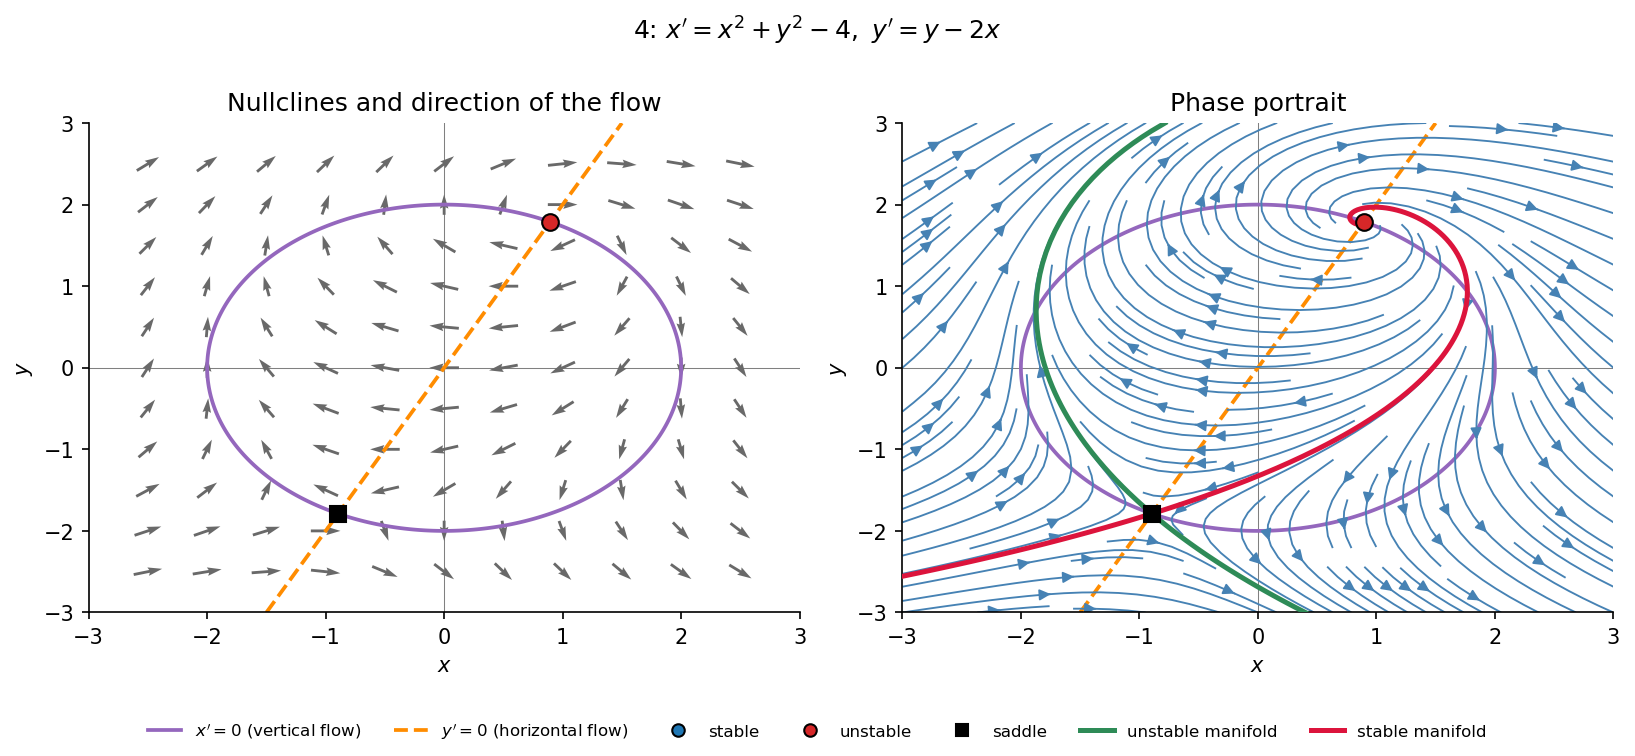

In [17]:
nullcline_and_portrait(f4, g4, (-3, 3), (-3, 3), r"4: $x'=x^2+y^2-4,\ y'=y-2x$", pts_with_J(f4, g4, pts))

The phase portrait agrees with the analysis. Orbits spiral away from
$P_+$, clockwise. One branch of the stable manifold of the saddle $P_-$
(red) emerges from the spiral source $P_+$ and the other comes in from
the lower left. The unstable manifold (green) carries orbits away upward
along the left side of the circle and to the lower right.

## References

## Session Info

In [18]:
import sys, platform
print("Python", sys.version.split()[0], "on", platform.system())
print("NumPy", np.__version__, "| SciPy", sp.__version__, "| SymPy", sym.__version__, "| Matplotlib", mpl.__version__)

Python 3.14.4 on Darwin
NumPy 2.4.3 | SciPy 1.17.1 | SymPy 1.14.0 | Matplotlib 3.10.8

## Reuse

[![](http://mirrors.creativecommons.org/presskit/buttons/88x31/png/by-nc-sa.png?raw=1)](https://creativecommons.org/licenses/by-nc-sa/4.0/legalcode)

[CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/)